# Using the Profile-Scan Uncertainty Scanner with SasModels and Bumps

## Two simple examples: sphere and cylinder

This notebook demonstrates the workflow used by a typical SasView/SasModels model with Bumps:

1. Load a built-in SasModels model with `load_model()`.
2. Create a Bumps-compatible model with `sasmodels.bumps_model.Model`.
3. Connect the model to the data with `Experiment`.
4. Create a Bumps optimization problem with `bumps.names.FitProblem`.
5. Fit the model with `bp.fit()`.
6. Pass the fitted `FitProblem` and fit result to `ProfileLiklehoodScanner`.

No custom curve functions are defined here. The examples use the built-in SasModels `sphere` and `cylinder` models so that the connection to Bumps is explicit.

The data are generated synthetically inside the notebook with SasModels. They are not experimental measurements. Because the data are simulated, the parameter values used to generate them are known.

> **Requirements:** Place this notebook, `profile_liklehood_scan.py`, and `profile_liklehood_plot_mpl.py` in the same directory. The filenames and class name intentionally use the spelling `liklehood` to match the files in this project.

## 1. Imports and shared settings

Here, `SASModel` is an alias for `sasmodels.bumps_model.Model`. This class creates the Bumps parameters for the loaded SasModels model. `Experiment` connects the model to the data, and `FitProblem` turns the experiment into an optimization problem for Bumps.

The scanner itself is independent of the particular SasModels model stored in the `FitProblem`.

In [38]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import bumps.names as bp

from sasmodels.core import load_model
from sasmodels.data import empty_data1D
from sasmodels.direct_model import DirectModel
from sasmodels.bumps_model import Model as SASModel, Experiment

from profile_liklehood_scan import ProfileLiklehoodScanner
from profile_liklehood_plot_mpl import (
    plot_bumps_fit,
    plot_profile,
    plot_profile_comparison,
)

RANDOM_SEED = 20261109
FIT_METHOD = "amoeba"
FIT_OPTIONS = {"steps": 600, "starts": 1, "parallel": 1, "verbose": False}
PROFILE_OPTIMIZER = "L-BFGS-B"
PROFILE_OPTIONS = {"maxiter": 1500, "ftol": 1e-9}

print("Scanner class:", ProfileLiklehoodScanner.__name__)
print("Fit method:", FIT_METHOD)

Scanner class: ProfileLiklehoodScanner
Fit method: amoeba


## 2. Helper functions for synthetic SasModels data

The synthetic data are calculated with the same SasModels kernel that is fitted later. This creates a controlled test case: the generating parameter values are known.

`empty_data1D(q)` creates a 1D data object for the requested q grid. `DirectModel` calculates the model intensity on that grid. We then add a small, reproducible Gaussian error and store the measured intensity and its uncertainty in the data object.

This function only generates the data. The fit model is built separately later, using different starting values.

In [39]:
def make_synthetic_data(model_name, q, true_parameters, seed, relative_error=0.03):
    """Generate reproducible 1D data with a built-in SasModels kernel."""
    kernel = load_model(model_name)
    q_grid = empty_data1D(q)

    calculator = DirectModel(q_grid, kernel)
    theory = np.asarray(calculator(**true_parameters), dtype=float)

    rng = np.random.default_rng(seed)
    uncertainty = np.maximum(np.abs(theory) * relative_error, 1e-4)
    measured_intensity = theory + rng.normal(0.0, uncertainty)

    data = empty_data1D(q)
    data.y = measured_intensity
    data.dy = uncertainty
    return data, theory


def fix_all_but(model, free_parameter_names):
    """Keep only the named parameters variable in a SasModels Bumps model."""
    free_parameter_names = set(free_parameter_names)
    for name, parameter in model.parameters().items():
        if name not in free_parameter_names:
            parameter.fixed = True


def run_bumps_fit(problem):
    """Run the common Bumps fit and store its solution in the FitProblem."""
    result = bp.fit(problem, method=FIT_METHOD, **FIT_OPTIONS)
    problem.setp(np.asarray(result.x, dtype=float))
    return result


def show_fit_parameters(problem):
    """Print fitted Bumps parameter names and values."""
    labels = [str(label) for label in problem.labels()]
    values = np.asarray(problem.getp(), dtype=float)
    for label, value in zip(labels, values):
        print(f"{label:24s} {value:.8g}")


def get_parameter_label(problem, short_name):
    """Find the unique Bumps label ending in a SasModels parameter name."""
    labels = [str(label) for label in problem.labels()]
    matches = [label for label in labels if label == short_name or label.endswith("." + short_name)]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one Bumps parameter matching '{short_name}', found: {labels}"
        )
    return matches[0]


def make_scanner(problem, fit_result, parameter_name, lower, upper):
    """Create the scanner using the fitted Bumps FitProblem."""
    return ProfileLiklehoodScanner(
        problem=problem,
        target_param_name=parameter_name,
        min_bound=lower,
        max_bound=upper,
        best_fit_result=fit_result,
        optimizer_method=PROFILE_OPTIMIZER,
        optimizer_options=PROFILE_OPTIONS,
    )

**Units:** The built-in SasModels use numerical values for `sld` and `sld_solvent` in units of 10⁻⁶ Å⁻². Thus, `4.0` means 4 × 10⁻⁶ Å⁻²; do not enter `4e-6` here. The sphere radius is specified in Å. See the [SasView description of the `sphere` model](https://www.sasview.org/docs/old_docs/6.0.0/user/models/sphere.html).

## 3. Example 1 – SasModels `sphere`

We generate data for a sphere with a known radius. For the fit, only `radius`, `scale`, and `background` are allowed to vary. All other model parameters – especially the scattering length densities and polydispersity parameters – remain fixed.

This first example is deliberately kept simple: the scanner profiles `radius`; `scale` and `background` are re-optimized at every profile point.

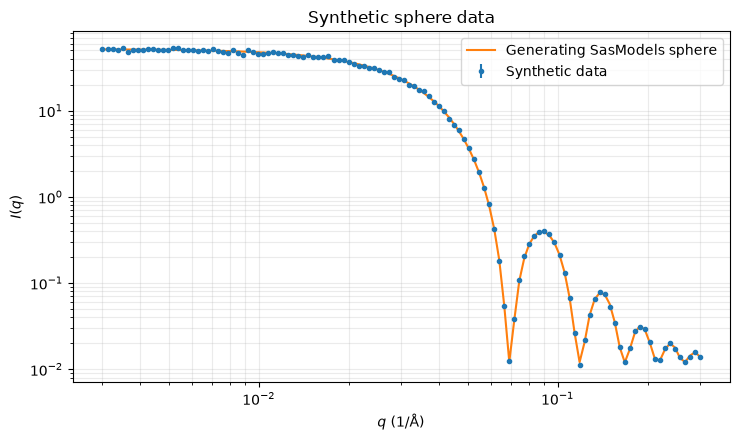

In [40]:
q_sphere = np.logspace(np.log10(0.003), np.log10(0.30), 120)

sphere_truth = {
    "scale": 0.050,
    "background": 0.012,
    "radius": 65.0,
    "sld": 4.0,
    "sld_solvent": 1.0,
}

data_sphere, theory_sphere = make_synthetic_data(
    model_name="sphere",
    q=q_sphere,
    true_parameters=sphere_truth,
    seed=RANDOM_SEED + 1,
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.errorbar(data_sphere.x, data_sphere.y, yerr=data_sphere.dy, fmt="o", ms=3, label="Synthetic data")
ax.plot(data_sphere.x, theory_sphere, label="Generating SasModels sphere")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$q$ (1/Å)")
ax.set_ylabel(r"$I(q)$")
ax.set_title("Synthetic sphere data")
ax.legend()
ax.grid(True, which="both", alpha=0.25)
fig.tight_layout()
plt.show()

### 3.1 Build the SasModels model as a Bumps FitProblem

The three key steps are:

```python
kernel = load_model("sphere")
model = SASModel(kernel, ...)
experiment = Experiment(data=data_sphere, model=model)
problem = bp.FitProblem(experiment)
```

Set parameter bounds directly on the Bumps parameters. The helper `fix_all_but()` keeps all other parameters fixed so that the example remains easy to follow.

In [41]:
sphere_kernel = load_model("sphere")
sphere_model = SASModel(
    sphere_kernel,
    scale=0.035,
    background=0.020,
    radius=52.0,
    sld=4.0,
    sld_solvent=1.0,
)

sphere_free_parameters = {"radius", "scale", "background"}
fix_all_but(sphere_model, sphere_free_parameters)

sphere_model.radius.range(20.0, 100.0)
sphere_model.scale.range(0.005, 0.15)
sphere_model.background.range(0.0, 0.10)

sphere_experiment = Experiment(
    data=data_sphere,
    model=sphere_model,
    name="Synthetic sphere",
)
sphere_problem = bp.FitProblem(sphere_experiment)

print("Bumps labels:", sphere_problem.labels())
print("Bumps bounds (lower row, upper row):")
print(sphere_problem.bounds())

Bumps labels: ['background', 'radius', 'scale']
Bumps bounds (lower row, upper row):
[[0.0e+00 2.0e+01 5.0e-03]
 [1.0e-01 1.0e+02 1.5e-01]]


### 3.2 Run the Bumps fit

`bp.fit()` optimizes the parameter vector jointly. We then explicitly write `result.x` back into the `FitProblem`. The native Bumps/SasModels fit plot shows how well the model describes the data.

Fitted sphere parameters:
background               0.012049209
radius                   65.042644
scale                    0.050021671
Bumps nllf: 57.805995765683974


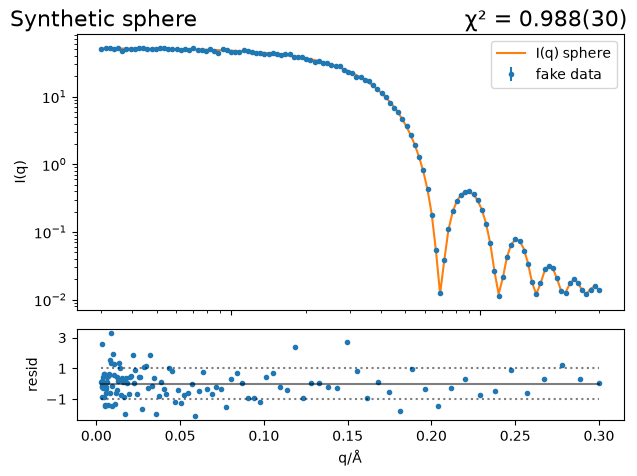

In [42]:
sphere_fit = run_bumps_fit(sphere_problem)

print("Fitted sphere parameters:")
show_fit_parameters(sphere_problem)
print("Bumps nllf:", float(sphere_problem.nllf()))

sphere_fit_figure = plot_bumps_fit(
    sphere_problem,
    sphere_fit,
    show=True,
)



## 3.3 Understand the scan control parameters

The scanner provides several settings that control how the profile likelihood is calculated.

| Input | Meaning |
|---|---|
| `max_steps` | Maximum number of scan steps in each direction from the best-fit value |
| `initial_step_fraction` | Initial step size as a fraction of the total scan interval |
| `max_step_fraction` | Maximum permitted adaptive step size as a fraction of the total scan interval |
| `threshold` | Profile-likelihood threshold at which the scan can stop |

The step sizes are calculated relative to the scan interval.

For example, with a scan interval from 20 to 100 Å, the interval width is 80 Å.

- `initial_step_fraction=5e-4` corresponds to an initial step size of 0.04 Å.
- `max_step_fraction=2e-2` corresponds to a maximum step size of 1.6 Å.

The scanner adaptively changes its step size during the scan. Therefore, `max_steps` specifies an upper limit, not an exact number of points.

The scan can stop earlier when the threshold is reached or a parameter boundary is encountered.

## 3.4. Run a coarse scan

A coarse scan uses larger steps and is useful for obtaining an overview of the profile likelihood.

```python
sphere_scanner_coarse = make_scanner(**sphere_common_scan)

sphere_scanner_coarse.run_scan(
    max_steps=555,
    initial_step_fraction=5e-4,
    max_step_fraction=2e-2,
    threshold=4.0,
)

sphere_scanner_coarse.extract_uncertainties()
```

The settings used here are:

- `max_steps=555`: Allows up to 555 steps in each scan direction.
- `initial_step_fraction=5e-4`: Starts with a relatively large step.
- `max_step_fraction=2e-2`: Allows the step size to increase up to 2% of the scan interval.
- `threshold=4.0`: Uses q = 4 as the stopping threshold.

## 3.5. Run a fine scan

A fine scan uses smaller steps and can provide a more detailed representation of the profile likelihood.

```python
sphere_scanner_fine = make_scanner(**sphere_common_scan)

sphere_scanner_fine.run_scan(
    max_steps=180,
    initial_step_fraction=5e-5,
    max_step_fraction=4e-3,
    threshold=4.0,
)

sphere_scanner_fine.extract_uncertainties()
```

Compared with the coarse scan, the initial and maximum step sizes are smaller:

- `initial_step_fraction=5e-5`: Initial step size of 0.004 Å.
- `max_step_fraction=4e-3`: Maximum step size of 0.32 Å.

The fine scan can therefore resolve more detail in the profile, although it may require more optimization steps.

## 3.6. Print the scan summary

After completing the scans, inspect the results.

```python
sphere_scanner_fine.print_summary()
```

You can also compare the number of calculated points:

```python
print("Coarse scan points:", len(sphere_scanner_coarse.results))
print("Fine scan points:", len(sphere_scanner_fine.results))
```

Remember that the number of points depends on the adaptive step sizes, the stopping threshold, and the parameter boundaries. A larger `max_steps` value does not necessarily produce more points.

## 3.7. Compare the coarse and fine profiles

Finally, plot both scans together.

```python
fig, ax = plot_profile_comparison(
    [sphere_scanner_fine, sphere_scanner_coarse],
    labels=["Fine scan", "Coarse scan"],
    title="SasModels sphere: radius profile",
    show=True,
)
```

The fine scan is plotted first and the coarse scan second, so the coarse scan is drawn on top when points overlap.

Comparing both profiles helps assess whether the coarse scan captures the overall shape and whether the fine scan reveals additional detail.


 PROFILE SCAN: radius (Index 1)
Scan points:                        211
Best-fit value:                           65.042644
q=1 interval:                      [65.021382, 65.063949]
Asymmetric uncertainty:         -0.021262 / +0.021306
q=4 boundaries:                         65.00016202609105 / 65.0852933945291
Reference: q = 2 * Delta(Bumps nllf); q=1 and q=4 are approximations.
Note: Bumps nllf may include prior and constraint contributions.
Scan right:                         q threshold reached
Scan left :                         q threshold reached



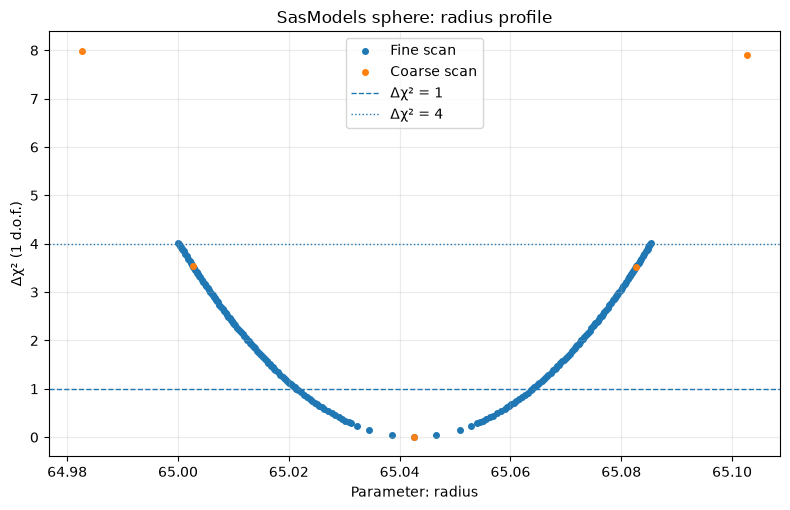

Coarse profile points: 5
Fine profile points: 211


In [67]:
sphere_radius_label = get_parameter_label(sphere_problem, "radius")

sphere_common_scan = {
    "problem": sphere_problem,
    "fit_result": sphere_fit,
    "parameter_name": sphere_radius_label,
    "lower": 20.0,
    "upper": 100.0,
}

sphere_scanner_coarse = make_scanner(**sphere_common_scan)
sphere_scanner_coarse.run_scan(
    max_steps=555,
    initial_step_fraction=5e-4,
    max_step_fraction=2e-2,
    threshold=4.0,
)
sphere_scanner_coarse.extract_uncertainties()

sphere_scanner_fine = make_scanner(**sphere_common_scan)
sphere_scanner_fine.run_scan(
    max_steps=180,
    initial_step_fraction=5e-5,
    max_step_fraction=4e-3,
    threshold=4.0,
)
sphere_scanner_fine.extract_uncertainties()

sphere_scanner_fine.print_summary()
fig, ax = plot_profile_comparison(
    [sphere_scanner_fine, sphere_scanner_coarse],
    labels=["Fine scan", "Coarse scan"],
    title="SasModels sphere: radius profile",
    show=True,
)
print("Coarse profile points:", len(sphere_scanner_coarse.results))
print("Fine profile points:", len(sphere_scanner_fine.results))

## 4. Example 2 – SasModels `cylinder`

The second example uses another built-in SasModels model. The procedure for building the Bumps problem is unchanged. We allow `radius`, `length`, `scale`, and `background` to vary, and then scan the cylinder length.

This demonstrates that the scanner is not tied to a particular model or parameter name. The other free parameters (`radius`, `scale`, and `background`) are re-optimized along the length profile.

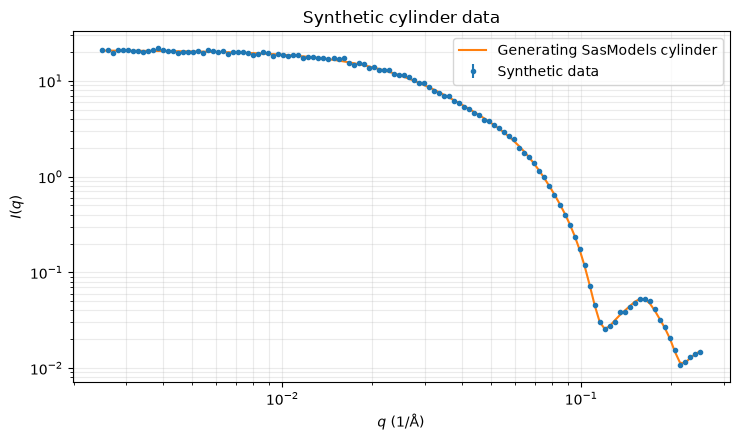

In [45]:
q_cylinder = np.logspace(np.log10(0.0025), np.log10(0.25), 120)

cylinder_truth = {
    "scale": 0.040,
    "background": 0.010,
    "radius": 32.0,
    "length": 180.0,
    "sld": 4.0,
    "sld_solvent": 1.0,
}

data_cylinder, theory_cylinder = make_synthetic_data(
    model_name="cylinder",
    q=q_cylinder,
    true_parameters=cylinder_truth,
    seed=RANDOM_SEED + 2,
)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.errorbar(data_cylinder.x, data_cylinder.y, yerr=data_cylinder.dy, fmt="o", ms=3, label="Synthetic data")
ax.plot(data_cylinder.x, theory_cylinder, label="Generating SasModels cylinder")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$q$ (1/Å)")
ax.set_ylabel(r"$I(q)$")
ax.set_title("Synthetic cylinder data")
ax.legend()
ax.grid(True, which="both", alpha=0.25)
fig.tight_layout()
plt.show()

### 4.1 Build and fit the cylinder model

As with the sphere, `load_model("cylinder")` returns the SasModels kernel. `SASModel` wraps it as a Bumps model. Bounds are set for the four free parameters; all remaining parameters stay fixed.

Bumps labels: ['background', 'length', 'radius', 'scale']
Bumps bounds (lower row, upper row):
[[0.0e+00 6.0e+01 1.0e+01 5.0e-03]
 [1.0e-01 4.0e+02 6.0e+01 1.2e-01]]
Fitted cylinder parameters:
background               0.010014355
length                   179.61786
radius                   32.012193
scale                    0.040153885
Bumps nllf: 50.181888897602605


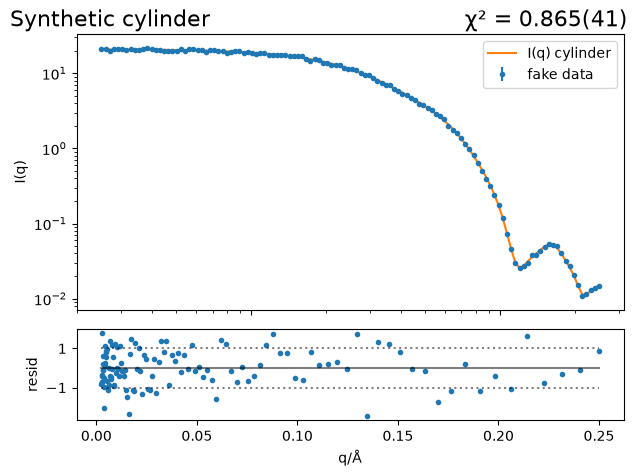

In [66]:
cylinder_kernel = load_model("cylinder")
cylinder_model = SASModel(
    cylinder_kernel,
    scale=0.028,
    background=0.018,
    radius=27.0,
    length=150.0,
    sld=4.0,
    sld_solvent=1.0,
)

cylinder_free_parameters = {"radius", "length", "scale", "background"}
fix_all_but(cylinder_model, cylinder_free_parameters)

cylinder_model.radius.range(10.0, 60.0)
cylinder_model.length.range(60.0, 400.0)
cylinder_model.scale.range(0.005, 0.12)
cylinder_model.background.range(0.0, 0.10)

cylinder_experiment = Experiment(
    data=data_cylinder,
    model=cylinder_model,
    name="Synthetic cylinder",
)
cylinder_problem = bp.FitProblem(cylinder_experiment)

print("Bumps labels:", cylinder_problem.labels())
print("Bumps bounds (lower row, upper row):")
print(cylinder_problem.bounds())

cylinder_fit = run_bumps_fit(cylinder_problem)
print("Fitted cylinder parameters:")
show_fit_parameters(cylinder_problem)
print("Bumps nllf:", float(cylinder_problem.nllf()))

cylinder_fit_figure = plot_bumps_fit(
    cylinder_problem,
    cylinder_fit,
    show=True,
)

### 4.2 Profile scan of the cylinder length

Only `length` is held fixed during this scan. The nuisance parameters `radius`, `scale`, and `background` are re-optimized at every scan point.


 PROFILE SCAN: length (Index 1)
Scan points:                        226
Best-fit value:                           179.61786
q=1 interval:                      [178.94544, 180.29308]
Asymmetric uncertainty:         -0.67243 / +0.67521
q=4 boundaries:                         178.27416439148337 / 180.97285179585415
Reference: q = 2 * Delta(Bumps nllf); q=1 and q=4 are approximations.
Note: Bumps nllf may include prior and constraint contributions.
Scan right:                         q threshold reached
Scan left :                         q threshold reached



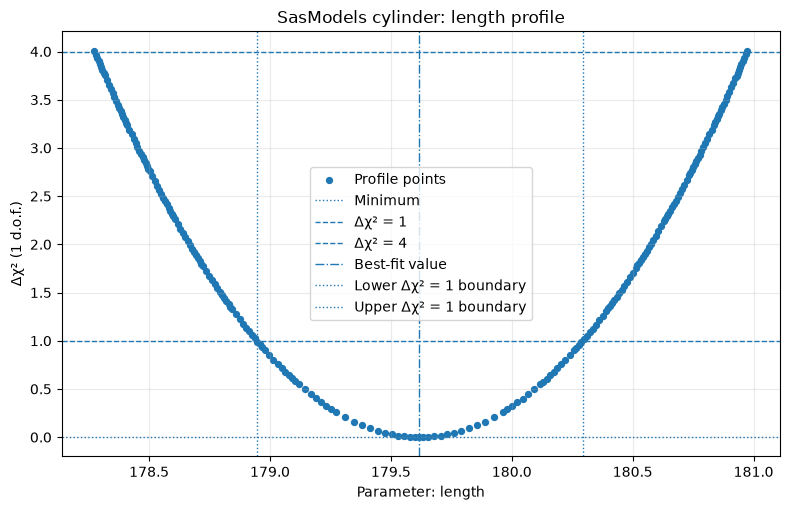

In [47]:
cylinder_length_label = get_parameter_label(cylinder_problem, "length")

cylinder_scanner = make_scanner(
    problem=cylinder_problem,
    fit_result=cylinder_fit,
    parameter_name=cylinder_length_label,
    lower=60.0,
    upper=400.0,
)

cylinder_scanner.run_scan(
    max_steps=180,
    initial_step_fraction=5e-5,
    max_step_fraction=4e-3,
    threshold=4.0,
)
cylinder_scanner.extract_uncertainties()
cylinder_scanner.print_summary()

fig, ax = plot_profile(
    cylinder_scanner,
    title="SasModels cylinder: length profile",
    show=True,
)

## 5. Adapting the example to your own data

When using experimental data, only the synthetic-data generation step is replaced. Instead of calling `make_synthetic_data(...)`, load a data object, for example with the SasModels data loader:

```python
from sasmodels.data import load_data

data = load_data("relative/or/absolute/path/to/measurement.dat")
```

The remaining model and scanner workflow stays the same:

```python
kernel = load_model("sphere")
model = SASModel(kernel, scale=..., background=..., radius=..., sld=..., sld_solvent=...)
model.radius.range(...)
experiment = Experiment(data=data, model=model, name="measurement")
problem = bp.FitProblem(experiment)
result = bp.fit(problem, method="amoeba", ...)
scanner = ProfileLiklehoodScanner(
    problem=problem,
    target_param_name="radius",
    min_bound=...,
    max_bound=...,
    best_fit_result=result,
)
```

The scan limits must lie within the Bumps bounds for the selected parameter and must include the fitted value. If a parameter name occurs more than once – for example, in a simultaneous fit – also provide `target_param_index`.

## 6. Interpretation and practical notes

- The scanner holds exactly one parameter fixed and re-optimizes all other free parameters. This is what distinguishes a profile scan from a simple slice in which all other parameters remain fixed.
- The step-size settings are fractions of the full scan range. The scanner also adjusts the step size adaptively while scanning.
- Under suitable likelihood and prior assumptions, `q = 1` and `q = 4` are the usual one-parameter thresholds corresponding approximately to 1σ and 2σ.
- `Bumps FitProblem.nllf()` may include prior and constraint contributions in addition to the data likelihood. With informative priors, the resulting limits should therefore not automatically be interpreted as frequentist profile-likelihood confidence intervals.
- The synthetic examples demonstrate the interface and workflow. They do not replace checking fit quality and model adequacy with real experimental data.
